In [1]:
# ============================================================
# Tahap 1
# IMPORT LIBRARY
# ============================================================

# pandas : mengolah data berbentuk tabel (DataFrame)
import pandas as pd
# numpy : perhitungan matriks dan angka
import numpy as np
# matplotlib : membuat grafik
import matplotlib.pyplot as plt
# pathlib : mengelola lokasi/nama file
from pathlib import Path
# display : menampilkan tabel dengan rapi di Jupyter/Colab
from IPython.display import display

In [2]:
# ============================================================
# Tahap 2
# UPLOAD DAN MEMBACA DATA DI GOOGLE COLAB
# ============================================================

# Modul khusus Google Colab untuk unggah/unduh file
from google.colab import files

print("Silakan unggah data berformat CSV atau Excel.")

# Membuka jendela unggah file milik Colab
uploaded = files.upload()

# Jika tidak ada file yang dipilih, hentikan proses
if len(uploaded) == 0:
    raise ValueError("Tidak ada file yang diunggah.")

# Mengambil nama file pertama yang diunggah
nama_file = next(iter(uploaded))
# Mengambil ekstensi file (.csv, .xlsx, dst.) dalam huruf kecil
ekstensi = Path(nama_file).suffix.lower()

if ekstensi == ".csv":
    # sep=None mencoba mendeteksi pemisah koma atau titik koma
    df_mentah = pd.read_csv(
        nama_file,
        sep=None,
        engine="python"
    )

elif ekstensi in [".xlsx", ".xls"]:
    # Membaca file Excel
    df_mentah = pd.read_excel(nama_file)

else:
    # Format selain CSV/Excel ditolak
    raise ValueError(
        "Format tidak didukung. Gunakan CSV, XLSX, atau XLS."
    )

# Membersihkan spasi pada nama-nama kolom
df_mentah.columns = (
    df_mentah.columns
    .astype(str)
    .str.strip()
)

# Menampilkan ringkasan data yang berhasil diunggah
print("\nData berhasil diunggah.")
print(f"Nama file    : {nama_file}")
print(f"Jumlah baris : {len(df_mentah)}")
print(f"Jumlah kolom : {len(df_mentah.columns)}")

display(df_mentah)

Silakan unggah data berformat CSV atau Excel.


Saving Latihan Soal_SAW.csv to Latihan Soal_SAW.csv

Data berhasil diunggah.
Nama file    : Latihan Soal_SAW.csv
Jumlah baris : 6
Jumlah kolom : 5


,Alternatif,C1,C2,C3,C4
0,Anto Kurnia Saputra,70,62,84,68
1,Budi Nugroho,50,76,82,76
2,Cika Dania Putri,82,53,78,71
3,Dian Pangeswari,89,68,73,86
4,Kartika Kusumatuti,75,72,86,74
5,Heru Sasongko,62,59,75,84


In [3]:
# ============================================================
# Tahap 3
# MENGUNGGAH DAN MENAMPILKAN DATA MENTAH
# ============================================================

print("\nData mentah:")
display(df_mentah)

print("\nDaftar kolom yang tersedia:")

# Menampilkan daftar kolom dengan nomor urut mulai dari 1
for nomor, nama_kolom in enumerate(df_mentah.columns, start=1):
    print(f"{nomor}. {nama_kolom}")


Data mentah:


,Alternatif,C1,C2,C3,C4
0,Anto Kurnia Saputra,70,62,84,68
1,Budi Nugroho,50,76,82,76
2,Cika Dania Putri,82,53,78,71
3,Dian Pangeswari,89,68,73,86
4,Kartika Kusumatuti,75,72,86,74
5,Heru Sasongko,62,59,75,84



Daftar kolom yang tersedia:
1. Alternatif
2. C1
3. C2
4. C3
5. C4


In [4]:
# ============================================================
# Tahap 4
# MEMILIH KOLOM IDENTITAS ALTERNATIF
# ============================================================

def pilih_kolom_alternatif(df):
    """
    Meminta pengguna memilih kolom yang menjadi
    identitas atau nama alternatif.
    """

    # Daftar seluruh nama kolom
    daftar_kolom = list(df.columns)

    print("\nPilih kolom yang menjadi identitas alternatif.")

    for nomor, kolom in enumerate(daftar_kolom, start=1):
        print(f"{nomor}. {kolom}")

    # Mengulang sampai pengguna memasukkan nomor yang valid
    while True:
        jawaban = input(
            "\nMasukkan nomor kolom alternatif: "
        ).strip()

        try:
            nomor_pilihan = int(jawaban)

            # Nomor valid: kembalikan nama kolom yang dipilih
            if 1 <= nomor_pilihan <= len(daftar_kolom):
                return daftar_kolom[nomor_pilihan - 1]

            print(
                f"Masukkan nomor antara 1 sampai "
                f"{len(daftar_kolom)}."
            )

        except ValueError:
            # Terjadi jika masukan bukan angka
            print("Masukkan nomor kolom yang valid.")


kolom_alternatif = pilih_kolom_alternatif(df_mentah)

print(
    f"\nKolom alternatif yang dipilih: "
    f"{kolom_alternatif}"
)


Pilih kolom yang menjadi identitas alternatif.
1. Alternatif
2. C1
3. C2
4. C3
5. C4

Masukkan nomor kolom alternatif: 1

Kolom alternatif yang dipilih: Alternatif


In [5]:
# ============================================================
# Tahap 5
# MEMILIH KOLOM KRITERIA
# ============================================================

def pilih_kolom_kriteria(df, kolom_alternatif):
    """
    Meminta pengguna menentukan kolom-kolom
    yang akan digunakan sebagai kriteria SAW.
    """

    # Kolom alternatif tidak boleh menjadi kriteria
    kolom_tersedia = [
        kolom for kolom in df.columns
        if kolom != kolom_alternatif
    ]

    print("\nPilih kolom yang akan digunakan sebagai kriteria.")

    for nomor, kolom in enumerate(kolom_tersedia, start=1):
        print(f"{nomor}. {kolom}")

    print(
        "\nMasukkan nomor kriteria dan pisahkan dengan koma."
    )
    print("Contoh: 1,2,4")

    # Mengulang sampai masukan valid
    while True:
        jawaban = input(
            "\nNomor kolom kriteria: "
        ).strip()

        try:
            # Memecah masukan "1,2,4" menjadi daftar angka [1, 2, 4]
            daftar_nomor = [
                int(nomor.strip())
                for nomor in jawaban.split(",")
            ]

            # Menghapus nomor duplikat tanpa mengubah urutan
            daftar_nomor = list(dict.fromkeys(daftar_nomor))

            if len(daftar_nomor) == 0:
                print("Pilih sekurang-kurangnya satu kriteria.")
                continue

            # Mencari nomor yang di luar rentang daftar kolom
            nomor_tidak_valid = [
                nomor for nomor in daftar_nomor
                if nomor < 1 or nomor > len(kolom_tersedia)
            ]

            if nomor_tidak_valid:
                print(
                    "Terdapat nomor kolom yang tidak valid:",
                    nomor_tidak_valid
                )
                continue

            # Mengubah nomor menjadi nama kolom
            kriteria_terpilih = [
                kolom_tersedia[nomor - 1]
                for nomor in daftar_nomor
            ]

            return kriteria_terpilih

        except ValueError:
            # Terjadi jika ada masukan yang bukan angka
            print(
                "Format tidak valid. "
                "Gunakan format seperti: 1,2,4"
            )


daftar_kriteria = pilih_kolom_kriteria(
    df_mentah,
    kolom_alternatif
)

print("\nKriteria yang dipilih:")

for nomor, kriteria in enumerate(daftar_kriteria, start=1):
    print(f"{nomor}. {kriteria}")


Pilih kolom yang akan digunakan sebagai kriteria.
1. C1
2. C2
3. C3
4. C4

Masukkan nomor kriteria dan pisahkan dengan koma.
Contoh: 1,2,4

Nomor kolom kriteria: 1,2,3,4

Kriteria yang dipilih:
1. C1
2. C2
3. C3
4. C4


In [6]:
# ============================================================
# Tahap 6
# VALIDASI DATA ALTERNATIF DAN KRITERIA
# ============================================================

def validasi_data_saw(
    df,
    kolom_alternatif,
    daftar_kriteria
):
    """
    Memvalidasi data sebelum dihitung menggunakan SAW.
    """

    # Mengambil hanya kolom alternatif dan kriteria (salinan data)
    data_saw = df[
        [kolom_alternatif] + daftar_kriteria
    ].copy()

    # Menghapus baris yang identitas alternatifnya kosong
    data_saw = data_saw.dropna(
        subset=[kolom_alternatif]
    )

    # Mengubah identitas alternatif menjadi teks
    data_saw[kolom_alternatif] = (
        data_saw[kolom_alternatif]
        .astype(str)
        .str.strip()
    )

    # Memeriksa nama alternatif duplikat
    duplikat = data_saw[
        kolom_alternatif
    ].duplicated(keep=False)

    if duplikat.any():
        alternatif_duplikat = (
            data_saw.loc[duplikat, kolom_alternatif]
            .unique()
            .tolist()
        )

        raise ValueError(
            "Terdapat identitas alternatif yang duplikat: "
            f"{alternatif_duplikat}"
        )

    # Mengubah seluruh nilai kriteria menjadi numerik
    # (nilai yang bukan angka menjadi NaN/kosong)
    for kolom in daftar_kriteria:
        data_saw[kolom] = pd.to_numeric(
            data_saw[kolom],
            errors="coerce"
        )

    # Memeriksa nilai kosong atau bukan angka
    nilai_tidak_valid = data_saw[
        daftar_kriteria
    ].isna()

    if nilai_tidak_valid.any().any():
        lokasi_error = []

        # Mencatat posisi setiap nilai yang bermasalah
        for indeks_baris, baris in nilai_tidak_valid.iterrows():
            for kolom, bermasalah in baris.items():
                if bermasalah:
                    lokasi_error.append(
                        {
                            # +2 karena baris 1 di Excel adalah header
                            "Baris Data": indeks_baris + 2,
                            "Alternatif": data_saw.loc[
                                indeks_baris,
                                kolom_alternatif
                            ],
                            "Kriteria": kolom
                        }
                    )

        print(
            "\nNilai berikut kosong atau tidak dapat "
            "dikonversi menjadi angka:"
        )
        display(pd.DataFrame(lokasi_error))

        raise ValueError(
            "Perbaiki nilai yang kosong atau bukan angka."
        )

    # SAW membutuhkan minimal dua alternatif untuk dibandingkan
    if len(data_saw) < 2:
        raise ValueError(
            "SAW memerlukan sekurang-kurangnya "
            "dua alternatif."
        )

    if len(daftar_kriteria) < 1:
        raise ValueError(
            "Pilih sekurang-kurangnya satu kriteria."
        )

    # Merapikan nomor indeks agar kembali berurutan dari 0
    return data_saw.reset_index(drop=True)


df_saw = validasi_data_saw(
    df_mentah,
    kolom_alternatif,
    daftar_kriteria
)

print("\nData yang akan diproses menggunakan SAW:")
display(df_saw)


Data yang akan diproses menggunakan SAW:


,Alternatif,C1,C2,C3,C4
0,Anto Kurnia Saputra,70,62,84,68
1,Budi Nugroho,50,76,82,76
2,Cika Dania Putri,82,53,78,71
3,Dian Pangeswari,89,68,73,86
4,Kartika Kusumatuti,75,72,86,74
5,Heru Sasongko,62,59,75,84


In [7]:
# ============================================================
# Tahap 7
# MENENTUKAN JENIS SETIAP KRITERIA
# ============================================================

def input_jenis_kriteria(daftar_kriteria):
    """
    Meminta pengguna memilih jenis benefit atau cost
    untuk masing-masing kriteria.
    """

    # Kamus: nama kriteria -> "benefit" atau "cost"
    jenis_kriteria = {}

    print("\nPenentuan jenis kriteria:")
    print("B = Benefit, semakin besar semakin baik")
    print("C = Cost, semakin kecil semakin baik")

    for kriteria in daftar_kriteria:
        # Mengulang sampai jawaban valid
        while True:
            jawaban = input(
                f"\nJenis kriteria '{kriteria}' [B/C]: "
            ).strip().lower()

            if jawaban in ["b", "benefit"]:
                jenis_kriteria[kriteria] = "benefit"
                break

            elif jawaban in ["c", "cost"]:
                jenis_kriteria[kriteria] = "cost"
                break

            else:
                print(
                    "Masukkan B untuk benefit "
                    "atau C untuk cost."
                )

    return jenis_kriteria


jenis_kriteria = input_jenis_kriteria(
    daftar_kriteria
)

print("\nJenis kriteria yang ditentukan:")

# Menampilkan jenis setiap kriteria dalam bentuk tabel
display(
    pd.DataFrame({
        "Kriteria": daftar_kriteria,
        "Jenis": [
            jenis_kriteria[kriteria]
            for kriteria in daftar_kriteria
        ]
    })
)


Penentuan jenis kriteria:
B = Benefit, semakin besar semakin baik
C = Cost, semakin kecil semakin baik

Jenis kriteria 'C1' [B/C]: b

Jenis kriteria 'C2' [B/C]: b

Jenis kriteria 'C3' [B/C]: b

Jenis kriteria 'C4' [B/C]: b

Jenis kriteria yang ditentukan:


,Kriteria,Jenis
0,C1,benefit
1,C2,benefit
2,C3,benefit
3,C4,benefit


In [8]:
# ============================================================
# Tahap 8
# MENENTUKAN DAN MENORMALISASI BOBOT KRITERIA
# ============================================================

def input_bobot_kriteria(daftar_kriteria):
    """
    Meminta pengguna memasukkan bobot tiap kriteria.

    Bobot tidak harus berjumlah 1 atau 100 karena sistem
    akan melakukan normalisasi bobot secara otomatis.
    """

    # Kamus: nama kriteria -> bobot sesuai masukan pengguna
    bobot_awal = {}

    print("\nMasukkan bobot setiap kriteria.")
    print(
        "Bobot dapat menggunakan skala apa pun, "
        "misalnya 5, 4, 3 atau 50, 30, 20."
    )

    for kriteria in daftar_kriteria:
        # Mengulang sampai bobot valid
        while True:
            jawaban = input(
                f"Bobot untuk '{kriteria}': "
            ).strip()

            # Mendukung desimal dengan koma
            jawaban = jawaban.replace(",", ".")

            try:
                nilai_bobot = float(jawaban)

                # Menolak nilai tak hingga atau NaN
                if not np.isfinite(nilai_bobot):
                    print("Bobot harus berupa angka yang valid.")
                    continue

                if nilai_bobot < 0:
                    print("Bobot tidak boleh bernilai negatif.")
                    continue

                bobot_awal[kriteria] = nilai_bobot
                break

            except ValueError:
                print("Masukkan bobot dalam bentuk angka.")

    total_bobot = sum(bobot_awal.values())

    if total_bobot <= 0:
        raise ValueError(
            "Total bobot harus lebih besar dari nol."
        )

    # Normalisasi agar total bobot menjadi 1
    bobot_normal = {
        kriteria: nilai / total_bobot
        for kriteria, nilai in bobot_awal.items()
    }

    return bobot_awal, bobot_normal


bobot_awal, bobot = input_bobot_kriteria(
    daftar_kriteria
)

# Tabel ringkasan: jenis, bobot masukan, dan bobot setelah normalisasi
tabel_bobot = pd.DataFrame({
    "Kriteria": daftar_kriteria,
    "Jenis": [
        jenis_kriteria[kriteria]
        for kriteria in daftar_kriteria
    ],
    "Bobot Masukan": [
        bobot_awal[kriteria]
        for kriteria in daftar_kriteria
    ],
    "Bobot Normalisasi": [
        bobot[kriteria]
        for kriteria in daftar_kriteria
    ]
})

print("\nKonfigurasi kriteria:")
display(tabel_bobot.round(4))

# Total bobot normalisasi seharusnya selalu 1
print(
    "Total bobot setelah normalisasi:",
    round(sum(bobot.values()), 6)
)


Masukkan bobot setiap kriteria.
Bobot dapat menggunakan skala apa pun, misalnya 5, 4, 3 atau 50, 30, 20.
Bobot untuk 'C1': 35
Bobot untuk 'C2': 30
Bobot untuk 'C3': 25
Bobot untuk 'C4': 10

Konfigurasi kriteria:


,Kriteria,Jenis,Bobot Masukan,Bobot Normalisasi
0,C1,benefit,35.0,0.35
1,C2,benefit,30.0,0.30
2,C3,benefit,25.0,0.25
3,C4,benefit,10.0,0.10


Total bobot setelah normalisasi: 1.0


In [9]:
# ============================================================
# Tahap 9
# KONFIRMASI KONFIGURASI SAW
# ============================================================

print("=" * 60)
print("RINGKASAN KONFIGURASI SAW")
print("=" * 60)

print(f"Kolom alternatif : {kolom_alternatif}")
print(f"Jumlah alternatif: {len(df_saw)}")
print(f"Jumlah kriteria  : {len(daftar_kriteria)}")

print("\nDaftar alternatif:")
display(df_saw[[kolom_alternatif]])

print("\nKonfigurasi kriteria:")
display(tabel_bobot.round(4))

# Meminta persetujuan pengguna sebelum perhitungan dilanjutkan
while True:
    konfirmasi = input(
        "\nApakah konfigurasi tersebut sudah benar? [Y/T]: "
    ).strip().lower()

    if konfirmasi in ["y", "ya"]:
        print("Konfigurasi disetujui. Perhitungan dilanjutkan.")
        break

    elif konfirmasi in ["t", "tidak"]:
        # Menghentikan program agar pengguna dapat mengulang pengaturan
        raise RuntimeError(
            "Perhitungan dihentikan. "
            "Jalankan kembali cell pengaturan yang ingin diubah."
        )

    else:
        print("Masukkan Y untuk ya atau T untuk tidak.")

RINGKASAN KONFIGURASI SAW
Kolom alternatif : Alternatif
Jumlah alternatif: 6
Jumlah kriteria  : 4

Daftar alternatif:


,Alternatif
0,Anto Kurnia Saputra
1,Budi Nugroho
2,Cika Dania Putri
3,Dian Pangeswari
4,Kartika Kusumatuti
5,Heru Sasongko



Konfigurasi kriteria:


,Kriteria,Jenis,Bobot Masukan,Bobot Normalisasi
0,C1,benefit,35.0,0.35
1,C2,benefit,30.0,0.30
2,C3,benefit,25.0,0.25
3,C4,benefit,10.0,0.10



Apakah konfigurasi tersebut sudah benar? [Y/T]: y
Konfigurasi disetujui. Perhitungan dilanjutkan.


In [10]:
# ============================================================
# Tahap 10
# NORMALISASI MATRIKS KEPUTUSAN
# ============================================================

def normalisasi_saw(
    df,
    kolom_alternatif,
    daftar_kriteria,
    jenis_kriteria
):
    """
    Melakukan normalisasi matriks keputusan
    menggunakan rumus SAW.
    """

    # Mengubah data kriteria menjadi matriks angka (array numpy)
    matriks = df[
        daftar_kriteria
    ].astype(float).to_numpy()

    # Matriks kosong (berisi 0) untuk menampung hasil normalisasi
    matriks_normalisasi = np.zeros_like(
        matriks,
        dtype=float
    )

    # Daftar untuk mencatat rincian rumus tiap sel
    rincian_normalisasi = []

    # Memproses satu kriteria (kolom) pada setiap putaran
    for j, kriteria in enumerate(daftar_kriteria):
        nilai_kolom = matriks[:, j]
        jenis = jenis_kriteria[kriteria]

        if jenis == "benefit":
            # Benefit: nilai dibagi nilai maksimum kolom
            nilai_maksimum = np.max(nilai_kolom)

            if nilai_maksimum == 0:
                raise ValueError(
                    f"Kriteria benefit '{kriteria}' memiliki "
                    "nilai maksimum 0 sehingga tidak dapat "
                    "dinormalisasi."
                )

            matriks_normalisasi[:, j] = (
                nilai_kolom / nilai_maksimum
            )

            # Mencatat rincian perhitungan tiap alternatif
            for i, nilai in enumerate(nilai_kolom):
                rincian_normalisasi.append({
                    "Alternatif": df.loc[
                        i,
                        kolom_alternatif
                    ],
                    "Kriteria": kriteria,
                    "Jenis": "Benefit",
                    "Perhitungan": (
                        f"{nilai:g} / {nilai_maksimum:g}"
                    ),
                    "Hasil": matriks_normalisasi[i, j]
                })

        elif jenis == "cost":
            # Cost: nilai minimum kolom dibagi nilai
            if np.any(nilai_kolom < 0):
                raise ValueError(
                    f"Kriteria cost '{kriteria}' mengandung "
                    "nilai negatif. Rumus min(x)/x tidak aman "
                    "untuk nilai negatif."
                )

            nilai_minimum = np.min(nilai_kolom)

            if nilai_minimum == 0:
                # Nilai 0 adalah cost terbaik.
                # Alternatif bernilai 0 memperoleh nilai 1,
                # sedangkan nilai yang lebih besar memperoleh 0.
                matriks_normalisasi[:, j] = np.where(
                    nilai_kolom == 0,
                    1.0,
                    0.0
                )

                for i, nilai in enumerate(nilai_kolom):
                    rincian_normalisasi.append({
                        "Alternatif": df.loc[
                            i,
                            kolom_alternatif
                        ],
                        "Kriteria": kriteria,
                        "Jenis": "Cost",
                        "Perhitungan": (
                            "1 karena nilai cost = 0"
                            if nilai == 0
                            else "0 karena nilai minimum cost = 0"
                        ),
                        "Hasil": matriks_normalisasi[i, j]
                    })

            else:
                # Kasus cost normal: minimum / nilai
                matriks_normalisasi[:, j] = (
                    nilai_minimum / nilai_kolom
                )

                for i, nilai in enumerate(nilai_kolom):
                    rincian_normalisasi.append({
                        "Alternatif": df.loc[
                            i,
                            kolom_alternatif
                        ],
                        "Kriteria": kriteria,
                        "Jenis": "Cost",
                        "Perhitungan": (
                            f"{nilai_minimum:g} / {nilai:g}"
                        ),
                        "Hasil": matriks_normalisasi[i, j]
                    })

        else:
            raise ValueError(
                f"Jenis kriteria '{kriteria}' tidak valid."
            )

    # Mengubah matriks hasil menjadi tabel dengan nama kolom kriteria
    df_normalisasi = pd.DataFrame(
        matriks_normalisasi,
        columns=daftar_kriteria
    )

    # Menambahkan kolom nama alternatif di posisi paling kiri
    df_normalisasi.insert(
        0,
        kolom_alternatif,
        df[kolom_alternatif].values
    )

    # Tabel rincian rumus normalisasi
    df_rincian = pd.DataFrame(
        rincian_normalisasi
    )

    return (
        matriks,
        matriks_normalisasi,
        df_normalisasi,
        df_rincian
    )


(
    matriks_keputusan,
    matriks_normalisasi,
    df_normalisasi,
    df_rincian_normalisasi
) = normalisasi_saw(
    df_saw,
    kolom_alternatif,
    daftar_kriteria,
    jenis_kriteria
)

print("\nMatriks keputusan:")
display(df_saw)

print("\nMatriks ternormalisasi:")
display(df_normalisasi.round(4))


Matriks keputusan:


,Alternatif,C1,C2,C3,C4
0,Anto Kurnia Saputra,70,62,84,68
1,Budi Nugroho,50,76,82,76
2,Cika Dania Putri,82,53,78,71
3,Dian Pangeswari,89,68,73,86
4,Kartika Kusumatuti,75,72,86,74
5,Heru Sasongko,62,59,75,84



Matriks ternormalisasi:


,Alternatif,C1,C2,C3,C4
0,Anto Kurnia Saputra,0.7865,0.8158,0.9767,0.7907
1,Budi Nugroho,0.5618,1.0000,0.9535,0.8837
2,Cika Dania Putri,0.9213,0.6974,0.9070,0.8256
3,Dian Pangeswari,1.0000,0.8947,0.8488,1.0000
4,Kartika Kusumatuti,0.8427,0.9474,1.0000,0.8605
5,Heru Sasongko,0.6966,0.7763,0.8721,0.9767


In [11]:
# ============================================================
# Tahap 11
# MENAMPILKAN RINCIAN PERHITUNGAN NORMALISASI
# ============================================================

# Menampilkan rincian rumus normalisasi per kriteria
for kriteria in daftar_kriteria:
    jenis = jenis_kriteria[kriteria].capitalize()

    print("\n" + "=" * 60)
    print(f"NORMALISASI {kriteria} ({jenis})")
    print("=" * 60)

    # Menyaring rincian hanya untuk kriteria yang sedang diproses
    rincian_kriteria = df_rincian_normalisasi[
        df_rincian_normalisasi["Kriteria"] == kriteria
    ][
        [
            "Alternatif",
            "Perhitungan",
            "Hasil"
        ]
    ].copy()

    display(rincian_kriteria.round({"Hasil": 4}))


NORMALISASI C1 (Benefit)


,Alternatif,Perhitungan,Hasil
0,Anto Kurnia Saputra,70 / 89,0.7865
1,Budi Nugroho,50 / 89,0.5618
2,Cika Dania Putri,82 / 89,0.9213
3,Dian Pangeswari,89 / 89,1.0000
4,Kartika Kusumatuti,75 / 89,0.8427
5,Heru Sasongko,62 / 89,0.6966



NORMALISASI C2 (Benefit)


,Alternatif,Perhitungan,Hasil
6,Anto Kurnia Saputra,62 / 76,0.8158
7,Budi Nugroho,76 / 76,1.0000
8,Cika Dania Putri,53 / 76,0.6974
9,Dian Pangeswari,68 / 76,0.8947
10,Kartika Kusumatuti,72 / 76,0.9474
11,Heru Sasongko,59 / 76,0.7763



NORMALISASI C3 (Benefit)


,Alternatif,Perhitungan,Hasil
12,Anto Kurnia Saputra,84 / 86,0.9767
13,Budi Nugroho,82 / 86,0.9535
14,Cika Dania Putri,78 / 86,0.9070
15,Dian Pangeswari,73 / 86,0.8488
16,Kartika Kusumatuti,86 / 86,1.0000
17,Heru Sasongko,75 / 86,0.8721



NORMALISASI C4 (Benefit)


,Alternatif,Perhitungan,Hasil
18,Anto Kurnia Saputra,68 / 86,0.7907
19,Budi Nugroho,76 / 86,0.8837
20,Cika Dania Putri,71 / 86,0.8256
21,Dian Pangeswari,86 / 86,1.0000
22,Kartika Kusumatuti,74 / 86,0.8605
23,Heru Sasongko,84 / 86,0.9767


In [12]:
# ============================================================
# Tahap 12
# MENGHITUNG NILAI PREFERENSI
# ============================================================

def hitung_preferensi_saw(
    df,
    kolom_alternatif,
    daftar_kriteria,
    matriks_normalisasi,
    bobot
):
    """
    Menghitung nilai preferensi setiap alternatif.
    """

    # Mengubah bobot menjadi vektor sesuai urutan kriteria
    vektor_bobot = np.array([
        bobot[kriteria]
        for kriteria in daftar_kriteria
    ])

    # Nilai preferensi = matriks normalisasi dikali vektor bobot
    nilai_preferensi = (
        matriks_normalisasi @ vektor_bobot
    )

    # Daftar untuk mencatat rincian perhitungan tiap alternatif
    rincian_preferensi = []

    for i, alternatif in enumerate(
        df[kolom_alternatif]
    ):
        komponen = []
        total = 0

        # Menjumlahkan (nilai normalisasi x bobot) tiap kriteria
        for j, kriteria in enumerate(daftar_kriteria):
            nilai_normalisasi = matriks_normalisasi[i, j]
            nilai_bobot = bobot[kriteria]
            hasil_kali = nilai_normalisasi * nilai_bobot

            total += hasil_kali

            komponen.append(
                f"({nilai_normalisasi:.4f} × "
                f"{nilai_bobot:.4f})"
            )

        rincian_preferensi.append({
            "Alternatif": alternatif,
            "Perhitungan": " + ".join(komponen),
            "Nilai Preferensi": total
        })

    df_preferensi = pd.DataFrame(
        rincian_preferensi
    )

    return nilai_preferensi, df_preferensi


nilai_preferensi, df_preferensi = (
    hitung_preferensi_saw(
        df_saw,
        kolom_alternatif,
        daftar_kriteria,
        matriks_normalisasi,
        bobot
    )
)

print("\nRincian nilai preferensi:")
display(df_preferensi.round({"Nilai Preferensi": 4}))


Rincian nilai preferensi:


,Alternatif,Perhitungan,Nilai Preferensi
0,Anto Kurnia Saputra,(0.7865 × 0.3500) + (0.8158 × 0.3000) + (0.976...,0.8433
1,Budi Nugroho,(0.5618 × 0.3500) + (1.0000 × 0.3000) + (0.953...,0.8234
2,Cika Dania Putri,(0.9213 × 0.3500) + (0.6974 × 0.3000) + (0.907...,0.8410
3,Dian Pangeswari,(1.0000 × 0.3500) + (0.8947 × 0.3000) + (0.848...,0.9306
4,Kartika Kusumatuti,(0.8427 × 0.3500) + (0.9474 × 0.3000) + (1.000...,0.9152
5,Heru Sasongko,(0.6966 × 0.3500) + (0.7763 × 0.3000) + (0.872...,0.7924


In [13]:
# ============================================================
# Tahap 13
# PERANGKINGAN ALTERNATIF
# ============================================================

# Tabel nama alternatif beserta nilai preferensinya
hasil = pd.DataFrame({
    "Alternatif": df_saw[kolom_alternatif],
    "Nilai Preferensi": nilai_preferensi
})

# Peringkat tertinggi diberikan kepada nilai terbesar
hasil["Peringkat"] = (
    hasil["Nilai Preferensi"]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

# Mengurutkan dari nilai terbesar (jika sama, urut nama alternatif)
hasil = (
    hasil
    .sort_values(
        by=[
            "Nilai Preferensi",
            "Alternatif"
        ],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("\nHasil akhir perangkingan SAW:")
display(hasil.round({"Nilai Preferensi": 4}))

# Baris pertama adalah alternatif terbaik
alternatif_terbaik = hasil.iloc[0]

print(
    f"\nAlternatif terbaik adalah "
    f"'{alternatif_terbaik['Alternatif']}' "
    f"dengan nilai preferensi "
    f"{alternatif_terbaik['Nilai Preferensi']:.4f}."
)


Hasil akhir perangkingan SAW:


,Alternatif,Nilai Preferensi,Peringkat
0,Dian Pangeswari,0.9306,1
1,Kartika Kusumatuti,0.9152,2
2,Anto Kurnia Saputra,0.8433,3
3,Cika Dania Putri,0.8410,4
4,Budi Nugroho,0.8234,5
5,Heru Sasongko,0.7924,6



Alternatif terbaik adalah 'Dian Pangeswari' dengan nilai preferensi 0.9306.


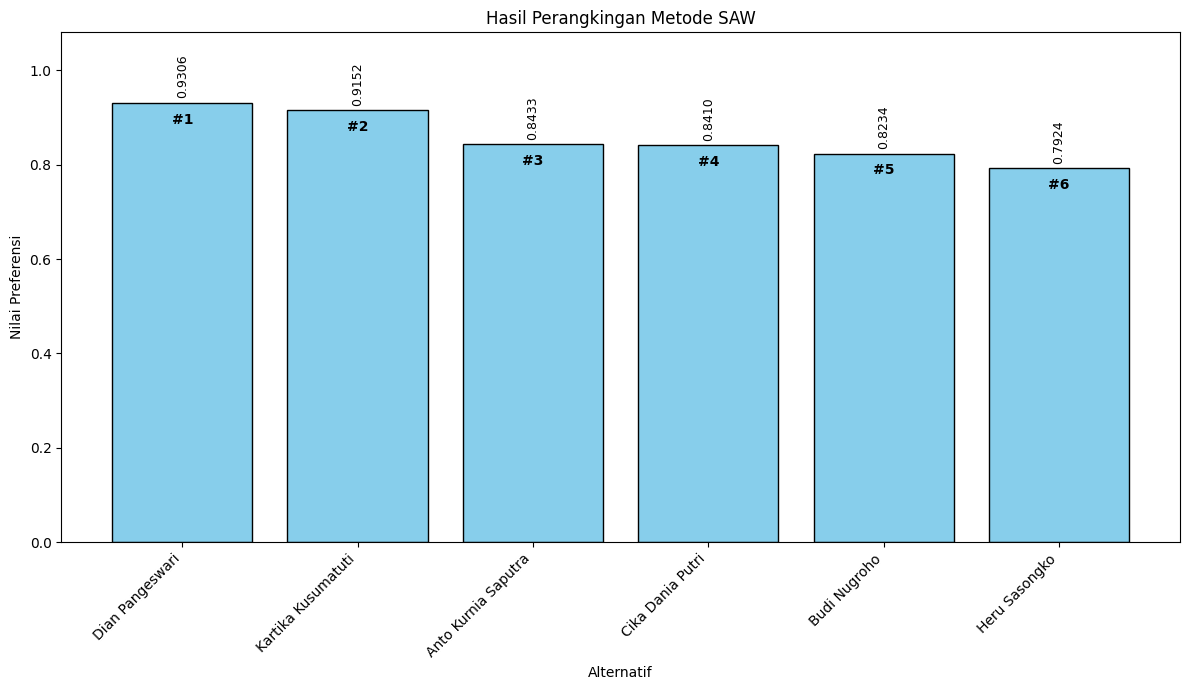

In [14]:
# ============================================================
# CELL 14
# VISUALISASI HASIL PERANGKINGAN
# ============================================================

# Jumlah maksimal alternatif yang ditampilkan pada grafik
# (ubah angka ini jika ingin menampilkan lebih sedikit/banyak)
batas_tampil = 15

# Tabel hasil sudah terurut dari nilai terbesar,
# sehingga head() mengambil peringkat teratas
hasil_grafik = hasil.head(batas_tampil)

# Judul grafik menyesuaikan jumlah alternatif yang ditampilkan
if len(hasil) > batas_tampil:
    judul_grafik = f"Hasil Perangkingan Metode SAW (Top {batas_tampil})"
    print(
        f"Grafik hanya menampilkan {batas_tampil} peringkat teratas "
        f"dari {len(hasil)} alternatif."
    )
else:
    judul_grafik = "Hasil Perangkingan Metode SAW"

# Membuat kanvas grafik berukuran 12 x 7 inci
plt.figure(figsize=(12, 7))

# Grafik batang nilai preferensi tiap alternatif
bars = plt.bar(
    hasil_grafik["Alternatif"].astype(str),
    hasil_grafik["Nilai Preferensi"],
    color="skyblue",
    edgecolor="black"
)

plt.xlabel("Alternatif")
plt.ylabel("Nilai Preferensi")
plt.title(judul_grafik)
# Batas sumbu Y: diberi ruang ekstra untuk teks nilai di atas batang
plt.ylim(
    0,
    max(1.0, hasil_grafik["Nilai Preferensi"].max() + 0.15)
)
# Memiringkan label sumbu X agar tidak bertumpuk
plt.xticks(rotation=45, ha="right")

# Menulis nilai (tegak, di atas batang) dan peringkat (di dalam batang)
for bar, nilai, peringkat in zip(
    bars,
    hasil_grafik["Nilai Preferensi"],
    hasil_grafik["Peringkat"]
):
    # Nilai preferensi ditulis tegak di atas batang
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{nilai:.4f}",
        ha="center",
        va="bottom",
        rotation=90,
        fontsize=9
    )

    # Peringkat ditulis singkat di dalam batang
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() - 0.02,
        f"#{peringkat}",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# Tahap 15
# MENGGABUNGKAN HASIL DENGAN DATA AWAL
# ============================================================

# Menggabungkan hasil perangkingan dengan data kriteria asli
hasil_lengkap = df_saw.merge(
    hasil,
    left_on=kolom_alternatif,
    right_on="Alternatif",
    how="left"
)

# Kolom "Alternatif" berlebih karena sudah ada kolom identitas asli
hasil_lengkap = hasil_lengkap.drop(
    columns=["Alternatif"]
)

# Mengurutkan berdasarkan peringkat terbaik
hasil_lengkap = hasil_lengkap.sort_values(
    by="Peringkat",
    ascending=True
).reset_index(drop=True)

print("\nHasil lengkap:")
display(
    hasil_lengkap.round({
        "Nilai Preferensi": 4
    })
)


Hasil lengkap:


,C1,C2,C3,C4,Nilai Preferensi,Peringkat
0,89,68,73,86,0.9306,1
1,75,72,86,74,0.9152,2
2,70,62,84,68,0.8433,3
3,82,53,78,71,0.8410,4
4,50,76,82,76,0.8234,5
5,62,59,75,84,0.7924,6


In [ ]:
# ============================================================
# Tahap 16
# MENYIMPAN HASIL KE EXCEL
# ============================================================

# Nama file keluaran (file lama dengan nama sama akan tertimpa)
nama_file_hasil = "hasil_perhitungan_saw.xlsx"

# Menulis semua tabel ke satu file Excel, satu sheet per tabel
with pd.ExcelWriter(
    nama_file_hasil,
    engine="openpyxl"
) as writer:

    df_mentah.to_excel(
        writer,
        sheet_name="Data Mentah",
        index=False
    )

    df_saw.to_excel(
        writer,
        sheet_name="Matriks Keputusan",
        index=False
    )

    tabel_bobot.to_excel(
        writer,
        sheet_name="Konfigurasi Kriteria",
        index=False
    )

    df_normalisasi.to_excel(
        writer,
        sheet_name="Matriks Normalisasi",
        index=False
    )

    df_rincian_normalisasi.to_excel(
        writer,
        sheet_name="Rincian Normalisasi",
        index=False
    )

    df_preferensi.to_excel(
        writer,
        sheet_name="Rincian Preferensi",
        index=False
    )

    hasil_lengkap.to_excel(
        writer,
        sheet_name="Hasil Perangkingan",
        index=False
    )

print(
    f"Hasil berhasil disimpan sebagai "
    f"'{nama_file_hasil}'."
)

# Jika dijalankan di Google Colab, file dapat langsung diunduh
try:
    from google.colab import files
    files.download(nama_file_hasil)
except ImportError:
    pass